# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in the case JSON).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [ ]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import simulation as sim
from utils.config import (
    FORCING,
    SIMULATIONS,
    get_offshore_wave,
    load_goals,
    open_offshore_waves,
    open_water_level,
    open_wind,
    resolve,
    simulation_model,
)

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in the case JSON → offshore_waves
period = slice("2012", "2014")  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
model = simulation_model()
templates_dir = sim.templates_dir("dynamic")
cases_dir = sim.cases_dir("dynamic")
grid_file = sim.grid_file()
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"model     : {model}")
print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"grid      : {grid_file}")
print(f"period    : {period}")

model     : snapwave
offshore  : WHACS → /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/WHACS/processed/Netherlands_WHACS_goal.zarr
goals     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Goals/Netherlands_Goals.json
templates : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/templates-snapwave-dynamic
cases     : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic
grid      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/Netherlands_mesh.nc
period    : slice('2012', '2014', None)


## Offshore waves → boundary forcing

In [3]:
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 51MB
Dimensions:   (time: 26304, goal: 10)
Coordinates:
  * time      (time) datetime64[ns] 210kB 2012-01-01 ... 2014-12-31T23:00:00
  * goal      (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    seapoint  (goal) int64 80B 2323617 2334975 2324234 ... 2326133 2326141
Data variables: (12/24)
    dir       (time, goal) float64 2MB 239.5 234.3 235.4 ... 259.0 264.5 269.4
    hs        (time, goal) float64 2MB 1.574 1.646 1.634 ... 2.056 2.002 1.918
    pdir0     (time, goal) float64 2MB 234.4 226.9 224.9 ... 259.0 264.5 269.4
    pdir1     (time, goal) float64 2MB 359.5 350.8 352.5 353.5 ... nan nan nan
    pdir2     (time, goal) float64 2MB nan nan 317.0 305.7 ... nan nan nan nan
    pdir3     (time, goal) float64 2MB nan nan nan nan nan ... nan nan nan nan
    ...        ...
    ptp0      (time, goal) float64 2MB 5.17 5.32 5.27 5.09 ... 6.31 6.29 6.24
    ptp1      (time, goal) float64 2MB 9.08 9.18 9.35 9.62 ... nan nan nan nan
    ptp2      (time, goal) float64 2MB nan nan 5.15 5.11 nan ... nan nan nan nan
    ptp3      (time, goal) float64 2MB nan nan nan nan nan ... nan nan nan nan
    spr       (time, goal) float64 2MB 36.8 41.3 44.4 47.9 ... 31.6 31.4 31.1
    tp        (time, goal) float64 2MB 5.208 5.348 5.291 ... 6.329 6.289 6.25
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
# One case per time step: per-goal (= boundary node) hs/tp/dir/spr lists + tref,
# and wl from forcing.water_level (CODEC; 0 where it has no value, after 2018)
metamodel_parameters = sim.dynamic_parameters(
    offshore_ds, water_level="water_level" in FORCING
)
list(metamodel_parameters.keys())

['hs_nodes', 'tp_nodes', 'dir_nodes', 'spr_nodes', 'wl_nodes', 'tref']

In [5]:
import numpy as np

n_cases = len(metamodel_parameters["tref"])
metamodel_parameters["save_map"] = np.random.choice(
    [True, False], size=n_cases, p=[0.05, 0.95]
).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(1368, 26304)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
# Case geometry: goals = boundary nodes, AoI enclosure, labelled output sites
setup = sim.HyWavesWrapperSetup.from_case(raw_goals)

# Wind field (forcing.wind, ERA5) at each case time; None runs without wind
wind = (
    open_wind(slice(offshore_ds.time.values[0], offshore_ds.time.values[-1]))
    if "wind" in FORCING
    else None
)
wrapper = setup.dynamic_wrapper(metamodel_parameters, wind=wind)
wrapper

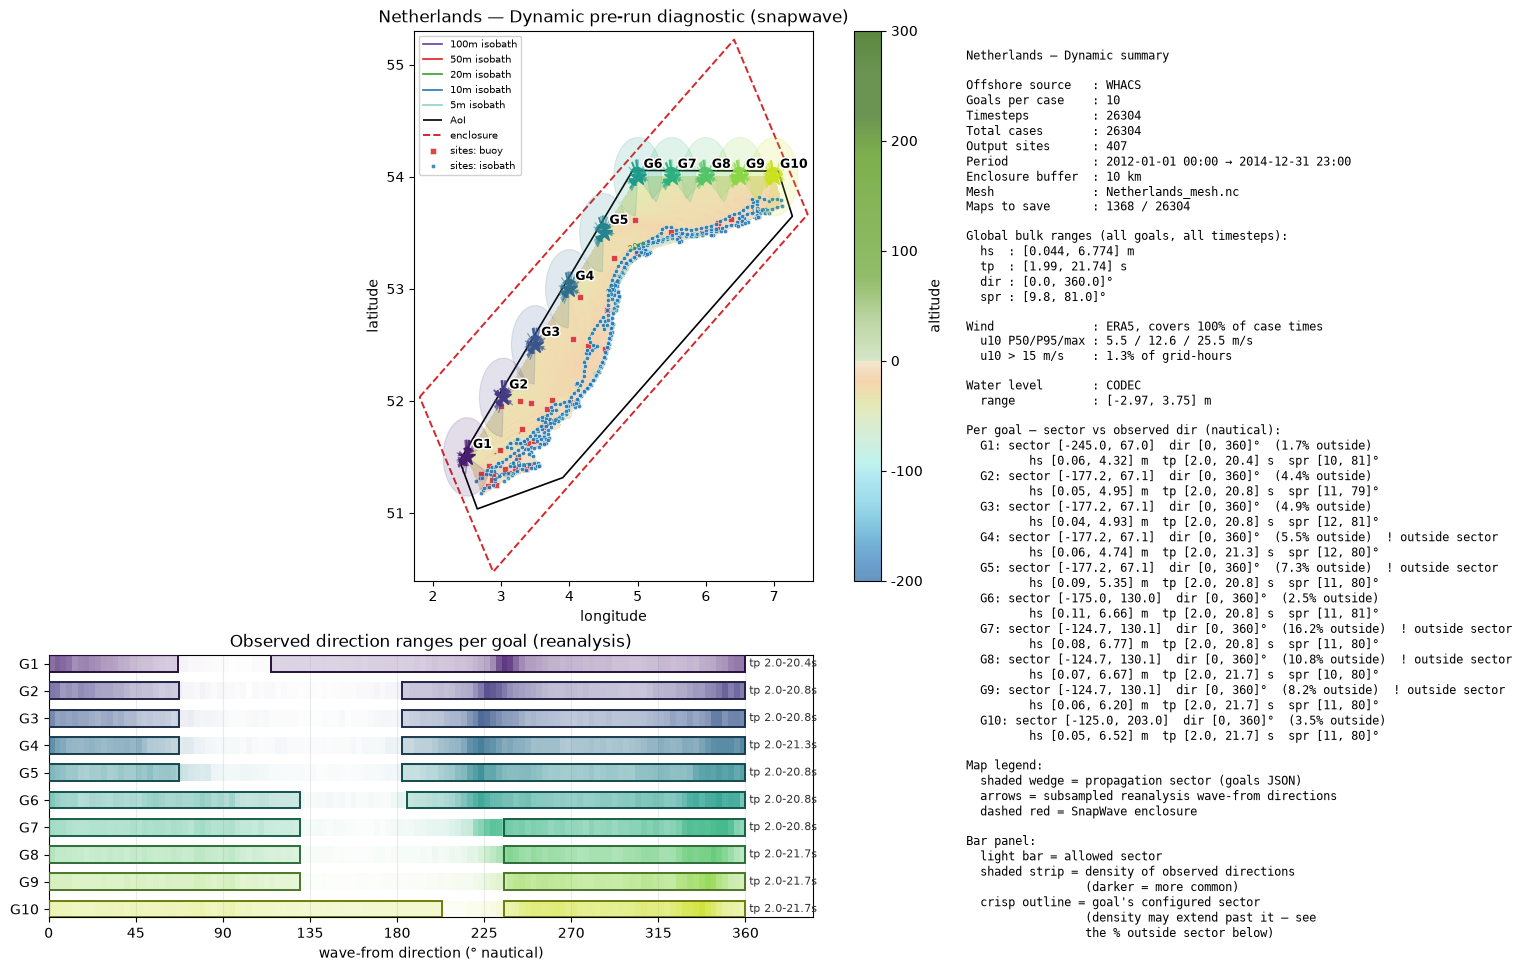

In [7]:
# Water level (forcing.water_level) at the goals, as given to the cases
water_level = open_water_level() if "water_level" in FORCING else None

fig = setup.plot_dynamic_configuration(
    offshore_ds,
    offshore_name=offshore_name,
    save_map=metamodel_parameters.get("save_map"),
    wind=wind,
    water_level=water_level,
)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
# On the GeoOcean cluster: one SLURM array task per case. Writes case_dirs.txt
# and the array script into the cases folder (options from
# simulations.<model>.slurm), then submits it with sbatch.
# wrapper.run_cases_slurm(**sim.slurm_kwargs(max_parallel=200))

In [10]:
# Or a few cases interactively ("geoocean-cluster" loads the snapwave module):
# wrapper.run_cases_in_background(
#     launcher="geoocean-cluster",
#     num_workers=3,
#     cases_to_run=[144, 454, 16100],
# )

In [11]:
wrapper.monitor_cases(value_counts="simple")

Status     
FINISHED       23330
NOT STARTED     2974
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


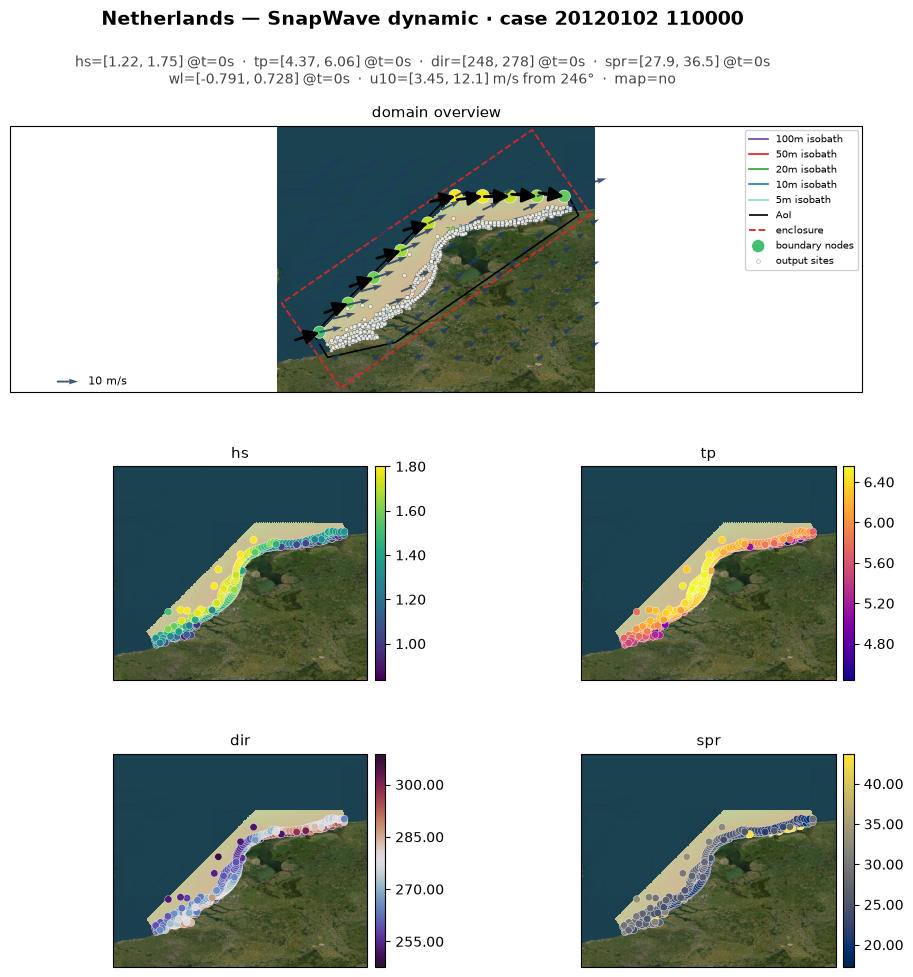

In [12]:
from bluemath_tk.wrappers.snapwave.snapwave_plots import CasePlotStyle
from utils.viz import plot_dynamic_case

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
plot_dynamic_case(
    "SnapWave_CASES_Dynamic/20120102 110000", style=style, show_satellite=True
);

In [13]:
result = wrapper.postprocess_cases(cases_to_postprocess=list(range(17544)))
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_2012-2013.nc"  # {'-'.join(period)}
result.to_netcdf(out_nc)

In [14]:
import xarray as xr

xr.open_dataset(out_nc).load().nbytes * 1e-9  # GB

0.11446502400000001